# Modèles Génératifs avec PyTorch — Première Partie
**TP : IA Générative Multi-Modale**

Plan :
0. Projet Python avec UV + dépendances
1. Chargement du dataset MNIST
2. Modèle discriminatif (classifieur)
3. Auto-encodeur simple
4. Variational Autoencoder (VAE)

## 0. Préparation de l'environnement

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

torch.manual_seed(42)

print("PyTorch :", torch.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)

PyTorch : 2.15.0+cpu
Device : cpu


## 1. Chargement du dataset MNIST

MNIST : 70 000 images de chiffres manuscrits (60 000 train / 10 000 test), en niveaux de gris, 28×28 pixels, 10 classes (0–9).

In [2]:
# Transformation : PIL -> tenseur float dans [0, 1], forme (1, 28, 28).
# On garde [0, 1] (pas de normalisation centrée) : c'est pratique pour
# les auto-encodeurs / VAE qui reconstruisent avec une sigmoïde + BCE.
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(root="data", train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root="data", train=False, download=True, transform=transform)

BATCH_SIZE = 128
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print("Taille train :", len(train_dataset))
print("Taille test  :", len(test_dataset))
print("Classes      :", train_dataset.classes)

Taille train : 60000
Taille test  : 10000
Classes      : ['0 - zero', '1 - one', '2 - two', '3 - three', '4 - four', '5 - five', '6 - six', '7 - seven', '8 - eight', '9 - nine']


Batch images : torch.Size([128, 1, 28, 28])
Batch labels : torch.Size([128])
Min / Max pixel : 0.0 1.0


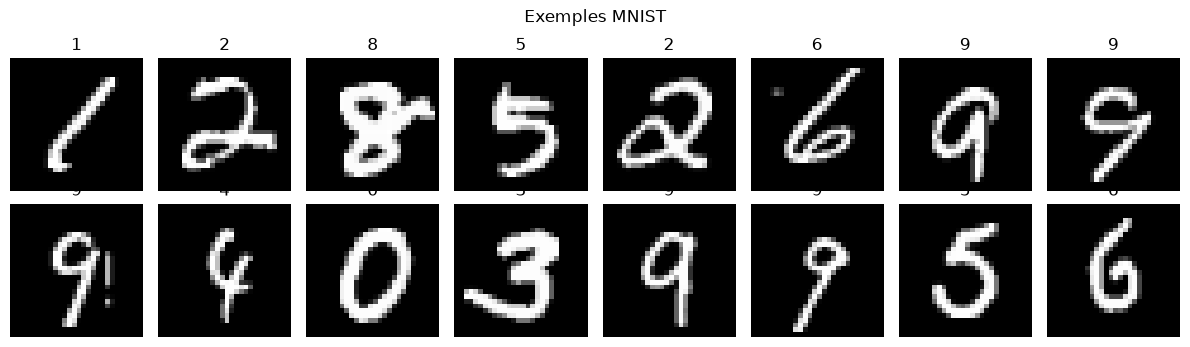

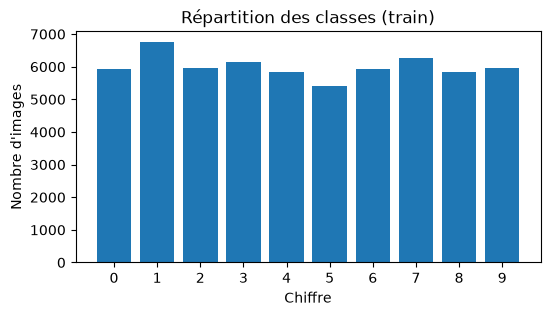

In [3]:
# Visualisation d'un batch
images, labels = next(iter(train_loader))
print("Batch images :", images.shape)   # (B, 1, 28, 28)
print("Batch labels :", labels.shape)
print("Min / Max pixel :", images.min().item(), images.max().item())

fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax, img, lbl in zip(axes.flat, images, labels):
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(int(lbl))
    ax.axis("off")
plt.suptitle("Exemples MNIST")
plt.tight_layout()
plt.show()

# Distribution des classes
counts = torch.bincount(train_dataset.targets, minlength=10)
plt.figure(figsize=(6, 3))
plt.bar(range(10), counts.numpy())
plt.xticks(range(10))
plt.xlabel("Chiffre")
plt.ylabel("Nombre d'images")
plt.title("Répartition des classes (train)")
plt.show()

## 2. Modèle discriminatif (classifieur)

Un modèle **discriminatif** apprend la distribution conditionnelle $p(y \mid x)$ : étant donnée une image $x$, il prédit la classe $y$. Il ne sait pas *générer* de nouvelles images — c'est le point de comparaison avec les modèles génératifs qui suivent, qui apprennent (une approximation de) $p(x)$.

On entraîne un petit CNN avec la cross-entropy.

In [4]:
class Classifier(nn.Module):
    """Petit CNN : 2 blocs conv + 2 couches denses -> 10 logits."""

    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),   # (32, 28, 28)
            nn.ReLU(),
            nn.MaxPool2d(2),                              # (32, 14, 14)
            nn.Conv2d(32, 64, kernel_size=3, padding=1),  # (64, 14, 14)
            nn.ReLU(),
            nn.MaxPool2d(2),                              # (64, 7, 7)
        )
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(128, 10),  # logits (la softmax est dans cross_entropy)
        )

    def forward(self, x):
        return self.head(self.features(x))


classifier = Classifier().to(device)
print(classifier)
print("Nombre de paramètres :", sum(p.numel() for p in classifier.parameters()))

Classifier(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Nombre de paramètres : 421642


In [5]:
EPOCHS_CLF = 3
optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3)
history_clf = {"loss": [], "acc": []}

for epoch in range(1, EPOCHS_CLF + 1):
    classifier.train()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        logits = classifier(x)
        loss = F.cross_entropy(logits, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * x.size(0)
        correct += (logits.argmax(dim=1) == y).sum().item()
        n += x.size(0)

    history_clf["loss"].append(total_loss / n)
    history_clf["acc"].append(correct / n)
    print(f"Époque {epoch}/{EPOCHS_CLF} - loss : {total_loss / n:.4f} - acc : {correct / n:.4f}")

Époque 1/3 - loss : 0.2794 - acc : 0.9127


Époque 2/3 - loss : 0.0733 - acc : 0.9777


Époque 3/3 - loss : 0.0529 - acc : 0.9840


C:\Users\yassi\tp-modeles-generatifs\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Accuracy test : 0.9881


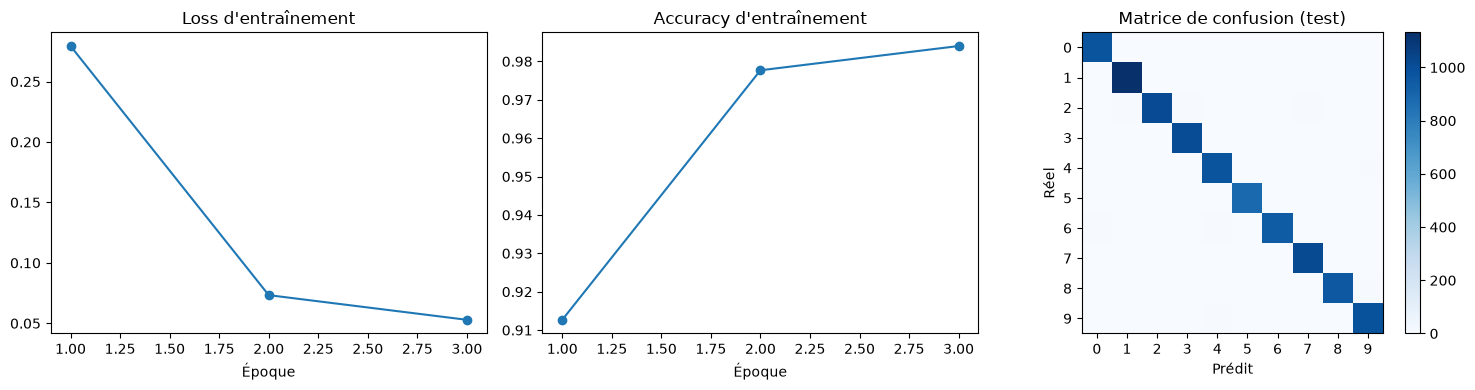

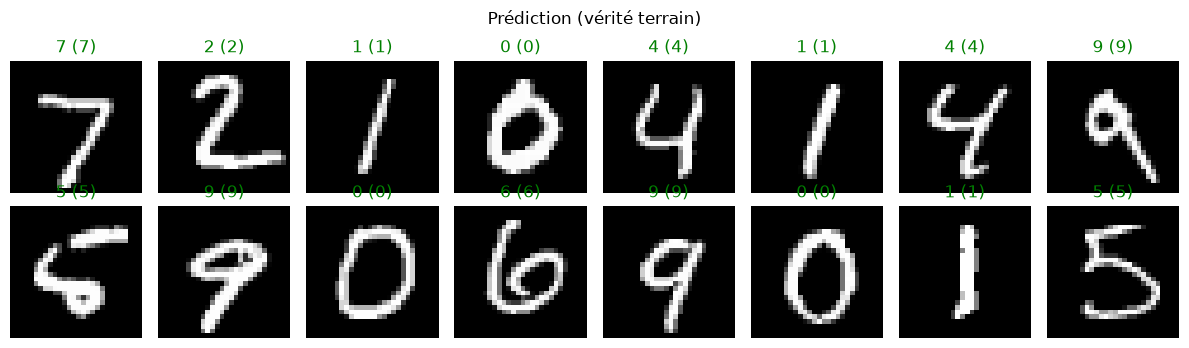

In [6]:
from torcheval.metrics import MulticlassAccuracy, MulticlassConfusionMatrix


@torch.no_grad()
def evaluate_classifier(model, loader):
    model.eval()
    acc = MulticlassAccuracy(num_classes=10)
    cm = MulticlassConfusionMatrix(num_classes=10)
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        preds = model(x).argmax(dim=1).cpu()
        acc.update(preds, y.cpu())
        cm.update(preds, y.cpu())
    return acc.compute().item(), cm.compute()


test_acc, conf_mat = evaluate_classifier(classifier, test_loader)
print(f"Accuracy test : {test_acc:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(range(1, EPOCHS_CLF + 1), history_clf["loss"], marker="o")
axes[0].set_title("Loss d'entraînement")
axes[0].set_xlabel("Époque")
axes[1].plot(range(1, EPOCHS_CLF + 1), history_clf["acc"], marker="o")
axes[1].set_title("Accuracy d'entraînement")
axes[1].set_xlabel("Époque")
im = axes[2].imshow(conf_mat.numpy(), cmap="Blues")
axes[2].set_title("Matrice de confusion (test)")
axes[2].set_xlabel("Prédit")
axes[2].set_ylabel("Réel")
axes[2].set_xticks(range(10))
axes[2].set_yticks(range(10))
fig.colorbar(im, ax=axes[2])
plt.tight_layout()
plt.show()

# Quelques prédictions sur le test set
x, y = next(iter(test_loader))
with torch.no_grad():
    preds = classifier(x.to(device)).argmax(dim=1).cpu()
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax, img, p, t in zip(axes.flat, x, preds, y):
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(f"{p.item()} ({t.item()})", color="green" if p == t else "red")
    ax.axis("off")
plt.suptitle("Prédiction (vérité terrain)")
plt.tight_layout()
plt.show()

## 3. Auto-encodeur simple

Un auto-encodeur apprend, **sans labels**, à compresser puis reconstruire une image :

$$x \xrightarrow{\text{encodeur } f_\phi} z \in \mathbb{R}^d \xrightarrow{\text{décodeur } g_\theta} \hat{x} \approx x$$

On minimise une erreur de reconstruction. Les pixels étant dans $[0, 1]$, on utilise la **binary cross-entropy** pixel par pixel (avec une sigmoïde en sortie du décodeur) :

$$\mathcal{L}(x) = \text{BCE}(\hat{x}, x)$$

On prend un espace latent de dimension $d = 2$ pour pouvoir le visualiser.

In [7]:
LATENT_DIM = 2  # 2D pour pouvoir visualiser directement l'espace latent


class Encoder(nn.Module):
    def __init__(self, latent_dim, out_mult=1):
        # out_mult=2 servira au VAE (mu et logvar)
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, latent_dim * out_mult),
        )

    def forward(self, x):
        return self.net(x)


class Decoder(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, 28 * 28),
            nn.Sigmoid(),  # pixels dans [0, 1]
        )

    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)


class AutoEncoder(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.encoder = Encoder(latent_dim)
        self.decoder = Decoder(latent_dim)

    def forward(self, x):
        return self.decoder(self.encoder(x))


autoencoder = AutoEncoder(LATENT_DIM).to(device)
print(autoencoder)
print("Nombre de paramètres :", sum(p.numel() for p in autoencoder.parameters()))

AutoEncoder(
  (encoder): Encoder(
    (net): Sequential(
      (0): Flatten(start_dim=1, end_dim=-1)
      (1): Linear(in_features=784, out_features=512, bias=True)
      (2): ReLU()
      (3): Linear(in_features=512, out_features=256, bias=True)
      (4): ReLU()
      (5): Linear(in_features=256, out_features=2, bias=True)
    )
  )
  (decoder): Decoder(
    (net): Sequential(
      (0): Linear(in_features=2, out_features=256, bias=True)
      (1): ReLU()
      (2): Linear(in_features=256, out_features=512, bias=True)
      (3): ReLU()
      (4): Linear(in_features=512, out_features=784, bias=True)
      (5): Sigmoid()
    )
  )
)
Nombre de paramètres : 1068306


Époque 1/10 - BCE train : 0.2219 - BCE test : 0.1946


Époque 2/10 - BCE train : 0.1901 - BCE test : 0.1866


Époque 3/10 - BCE train : 0.1840 - BCE test : 0.1826


Époque 4/10 - BCE train : 0.1804 - BCE test : 0.1801


Époque 5/10 - BCE train : 0.1776 - BCE test : 0.1772


Époque 6/10 - BCE train : 0.1759 - BCE test : 0.1764


Époque 7/10 - BCE train : 0.1743 - BCE test : 0.1742


Époque 8/10 - BCE train : 0.1732 - BCE test : 0.1734


Époque 9/10 - BCE train : 0.1725 - BCE test : 0.1731


Époque 10/10 - BCE train : 0.1713 - BCE test : 0.1718


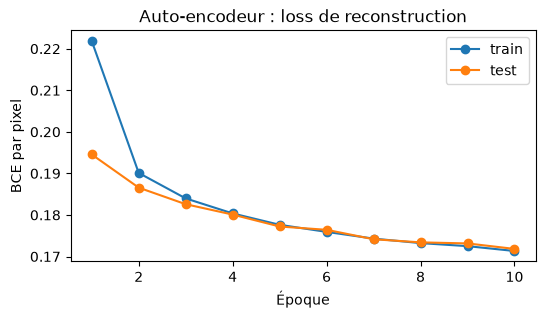

In [8]:
EPOCHS_AE = 10
optimizer = torch.optim.Adam(autoencoder.parameters(), lr=1e-3)
history_ae = {"train": [], "test": []}

for epoch in range(1, EPOCHS_AE + 1):
    autoencoder.train()
    total, n = 0.0, 0
    for x, _ in train_loader:  # les labels ne servent pas : apprentissage non supervisé
        x = x.to(device)
        x_hat = autoencoder(x)
        loss = F.binary_cross_entropy(x_hat, x)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item() * x.size(0)
        n += x.size(0)

    autoencoder.eval()
    with torch.no_grad():
        test_total = sum(
            F.binary_cross_entropy(autoencoder(x.to(device)), x.to(device), reduction="sum").item()
            for x, _ in test_loader
        ) / (len(test_dataset) * 28 * 28)

    history_ae["train"].append(total / n)
    history_ae["test"].append(test_total)
    print(f"Époque {epoch}/{EPOCHS_AE} - BCE train : {total / n:.4f} - BCE test : {test_total:.4f}")

plt.figure(figsize=(6, 3))
plt.plot(range(1, EPOCHS_AE + 1), history_ae["train"], marker="o", label="train")
plt.plot(range(1, EPOCHS_AE + 1), history_ae["test"], marker="o", label="test")
plt.xlabel("Époque")
plt.ylabel("BCE par pixel")
plt.title("Auto-encodeur : loss de reconstruction")
plt.legend()
plt.show()

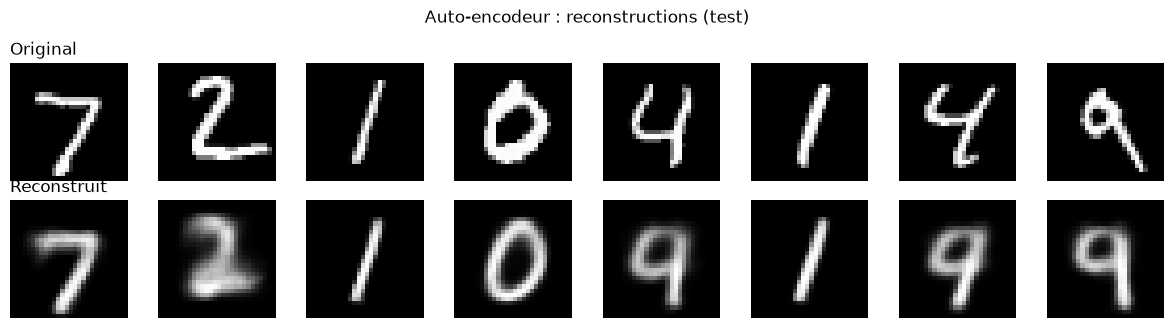

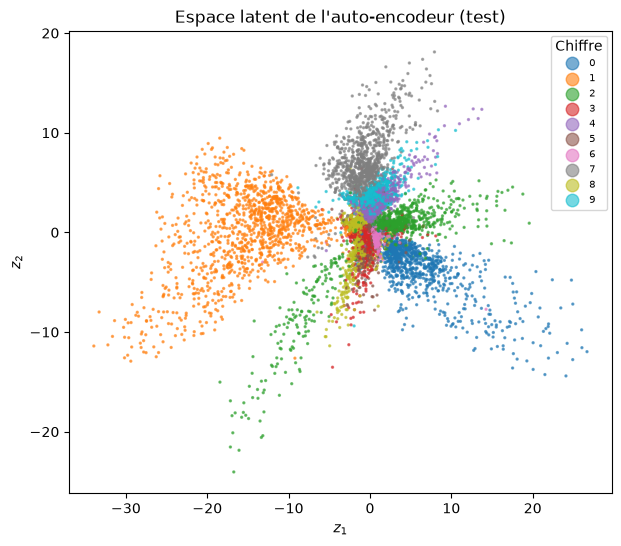

Moyenne des codes : [-1.0384375   0.66648346]  écart-type : [6.2933187 3.7443647]


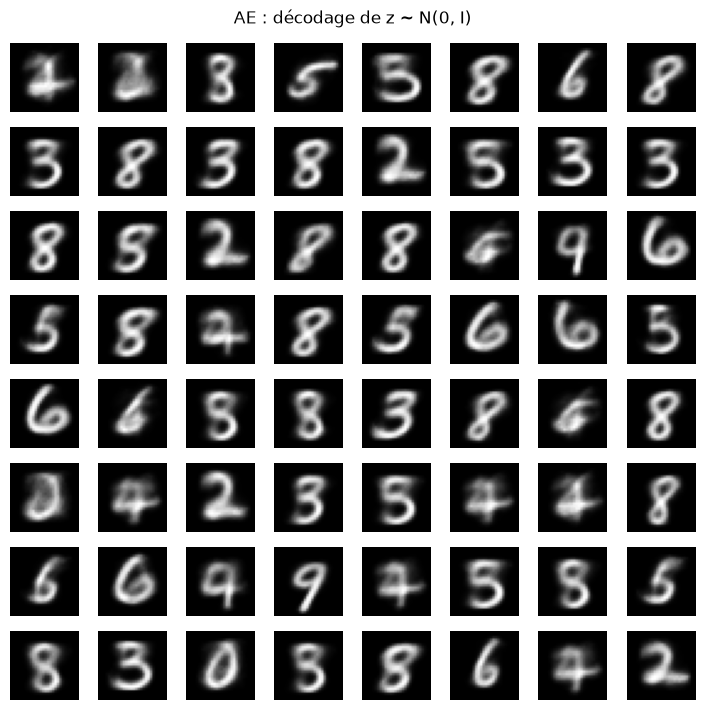

In [9]:
def show_reconstructions(model_fn, title, n=8):
    """Ligne du haut : originaux, ligne du bas : reconstructions."""
    x, _ = next(iter(test_loader))
    x = x[:n].to(device)
    with torch.no_grad():
        x_hat = model_fn(x).cpu()
    fig, axes = plt.subplots(2, n, figsize=(1.5 * n, 3.3))
    for i in range(n):
        axes[0, i].imshow(x[i].cpu().squeeze(), cmap="gray")
        axes[1, i].imshow(x_hat[i].squeeze(), cmap="gray")
        axes[0, i].axis("off")
        axes[1, i].axis("off")
    axes[0, 0].set_title("Original", loc="left")
    axes[1, 0].set_title("Reconstruit", loc="left")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


@torch.no_grad()
def encode_dataset(encode_fn, loader):
    zs, ys = [], []
    for x, y in loader:
        zs.append(encode_fn(x.to(device)).cpu())
        ys.append(y)
    return torch.cat(zs), torch.cat(ys)


def plot_latent(z, y, title, ax):
    sc = ax.scatter(z[:, 0], z[:, 1], c=y, cmap="tab10", s=2, alpha=0.6)
    ax.set_title(title)
    ax.set_xlabel("$z_1$")
    ax.set_ylabel("$z_2$")
    ax.legend(*sc.legend_elements(), title="Chiffre", loc="best", fontsize=7, markerscale=1.5)


def show_grid(images, title, nrow):
    """Affiche un tenseur (N, 1, 28, 28) en grille nrow x nrow."""
    fig, axes = plt.subplots(nrow, nrow, figsize=(nrow * 0.9, nrow * 0.9))
    for ax, img in zip(axes.flat, images):
        ax.imshow(img.squeeze(), cmap="gray")
        ax.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


# 1) Reconstructions
show_reconstructions(autoencoder, "Auto-encodeur : reconstructions (test)")

# 2) Espace latent
z_ae, y_ae = encode_dataset(autoencoder.encoder, test_loader)
fig, ax = plt.subplots(figsize=(7, 6))
plot_latent(z_ae, y_ae, "Espace latent de l'auto-encodeur (test)", ax)
plt.show()
print("Moyenne des codes :", z_ae.mean(dim=0).numpy(), " écart-type :", z_ae.std(dim=0).numpy())

# 3) "Génération" : on décode des z tirés au hasard selon N(0, I)
with torch.no_grad():
    z_rand = torch.randn(64, LATENT_DIM, device=device)
    samples_ae = autoencoder.decoder(z_rand).cpu()
show_grid(samples_ae, "AE : décodage de z ~ N(0, I)", nrow=8)

**Observations.**

- **Reconstructions** : correctes mais floues, et certaines classes proches se confondent (ex. les 4 reconstruits comme des 9) — avec $d = 2$, la compression est très forte et les classes 4/9 se chevauchent dans le latent.
- **Espace latent** : irrégulier. Les codes ne sont pas centrés-réduits (écart-type ≈ 6 et ≈ 4 selon les axes), les classes forment des « bras » d'étendues très différentes (les 1 vont jusqu'à $z_1 \approx -30$) avec des zones vides entre eux. Rien dans la loss n'impose une forme à cette distribution.
- **Échantillonnage** : comme on ne connaît pas la distribution des codes, on tire $z \sim \mathcal{N}(0, I)$… qui ne couvre que le petit cœur central de l'espace latent. Résultat : on obtient surtout des 8, 3, 5, 6 et des mélanges ambigus, et **aucun 1** (leur région est hors de portée). On ne peut pas échantillonner fidèlement la distribution des données.

L'auto-encodeur **compresse** bien mais n'est pas un vrai modèle **génératif** : il lui manque un *a priori* connu sur $z$ dont on pourrait tirer des échantillons. C'est exactement ce qu'ajoute le VAE.

## 4. Variational Autoencoder (VAE)

Le VAE est un vrai modèle génératif à variable latente :

$$z \sim p(z) = \mathcal{N}(0, I), \qquad x \sim p_\theta(x \mid z)$$

Le décodeur modélise $p_\theta(x \mid z)$ (Bernoulli par pixel → BCE). Comme la vraisemblance $p_\theta(x)$ est intractable, l'encodeur approxime la postérieure par une gaussienne diagonale :

$$q_\phi(z \mid x) = \mathcal{N}\big(\mu_\phi(x), \operatorname{diag}(\sigma^2_\phi(x))\big)$$

On maximise la borne inférieure de la log-vraisemblance (**ELBO**) :

$$\log p_\theta(x) \;\geq\; \underbrace{\mathbb{E}_{q_\phi(z\mid x)}\big[\log p_\theta(x \mid z)\big]}_{\text{reconstruction}} \;-\; \underbrace{D_{KL}\big(q_\phi(z \mid x)\,\|\,p(z)\big)}_{\text{régularisation}}$$

Pour deux gaussiennes, le terme KL a une forme fermée :

$$D_{KL} = -\frac{1}{2} \sum_{j=1}^{d} \left(1 + \log \sigma_j^2 - \mu_j^2 - \sigma_j^2\right)$$

**Astuce de reparamétrisation** : pour pouvoir rétro-propager à travers l'échantillonnage, on écrit $z = \mu + \sigma \odot \varepsilon$ avec $\varepsilon \sim \mathcal{N}(0, I)$.

Le terme KL force les codes à rester proches de $\mathcal{N}(0, I)$ : c'est ce qui permet ensuite de **générer** en tirant simplement $z \sim \mathcal{N}(0, I)$. On garde la même architecture et $d = 2$ que l'auto-encodeur pour une comparaison directe.

In [10]:
class VAE(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.latent_dim = latent_dim
        # Même architecture que l'AE, mais l'encodeur sort 2*d valeurs : mu et log(sigma^2)
        self.encoder = Encoder(latent_dim, out_mult=2)
        self.decoder = Decoder(latent_dim)

    def encode(self, x):
        h = self.encoder(x)
        mu, logvar = h.chunk(2, dim=1)
        return mu, logvar

    @staticmethod
    def reparameterize(mu, logvar):
        # z = mu + sigma * eps, eps ~ N(0, I) : le hasard est isolé dans eps,
        # donc le gradient peut passer par mu et sigma.
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + std * eps

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decoder(z), mu, logvar


def vae_loss(x_hat, x, mu, logvar):
    """-ELBO moyenné par image = reconstruction (BCE sommée sur les pixels) + KL."""
    batch_size = x.size(0)
    recon = F.binary_cross_entropy(x_hat, x, reduction="sum") / batch_size
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / batch_size
    return recon + kl, recon, kl


vae = VAE(LATENT_DIM).to(device)
print(vae)
print("Nombre de paramètres :", sum(p.numel() for p in vae.parameters()))

VAE(
  (encoder): Encoder(
    (net): Sequential(
      (0): Flatten(start_dim=1, end_dim=-1)
      (1): Linear(in_features=784, out_features=512, bias=True)
      (2): ReLU()
      (3): Linear(in_features=512, out_features=256, bias=True)
      (4): ReLU()
      (5): Linear(in_features=256, out_features=4, bias=True)
    )
  )
  (decoder): Decoder(
    (net): Sequential(
      (0): Linear(in_features=2, out_features=256, bias=True)
      (1): ReLU()
      (2): Linear(in_features=256, out_features=512, bias=True)
      (3): ReLU()
      (4): Linear(in_features=512, out_features=784, bias=True)
      (5): Sigmoid()
    )
  )
)
Nombre de paramètres : 1068820


Époque  1/15 - -ELBO train :  182.45 (recon  178.60 + KL  3.84) - -ELBO test :  163.56


Époque  2/15 - -ELBO train :  159.16 (recon  153.80 + KL  5.36) - -ELBO test :  155.65


Époque  3/15 - -ELBO train :  153.77 (recon  148.08 + KL  5.69) - -ELBO test :  152.09


Époque  4/15 - -ELBO train :  150.54 (recon  144.62 + KL  5.92) - -ELBO test :  149.58


Époque  5/15 - -ELBO train :  148.14 (recon  142.05 + KL  6.09) - -ELBO test :  147.47


Époque  6/15 - -ELBO train :  146.66 (recon  140.47 + KL  6.19) - -ELBO test :  146.69


... (5 outputs left out)

Époque 12/15 - -ELBO train :  141.96 (recon  135.43 + KL  6.53) - -ELBO test :  143.06


Époque 13/15 - -ELBO train :  141.64 (recon  135.06 + KL  6.58) - -ELBO test :  142.57


Époque 14/15 - -ELBO train :  141.24 (recon  134.64 + KL  6.60) - -ELBO test :  142.37


Époque 15/15 - -ELBO train :  140.75 (recon  134.10 + KL  6.65) - -ELBO test :  141.96


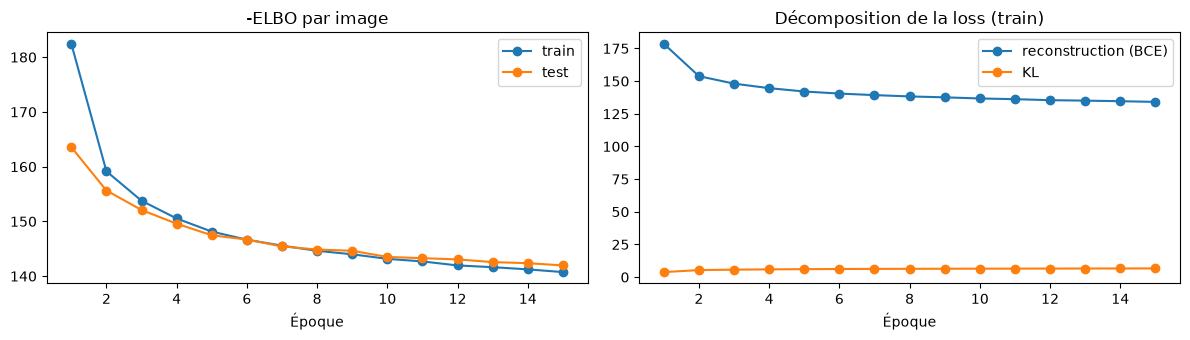

In [11]:
EPOCHS_VAE = 15
optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)
history_vae = {"loss": [], "recon": [], "kl": [], "test": []}

for epoch in range(1, EPOCHS_VAE + 1):
    vae.train()
    tot = {"loss": 0.0, "recon": 0.0, "kl": 0.0}
    for x, _ in train_loader:
        x = x.to(device)
        x_hat, mu, logvar = vae(x)
        loss, recon, kl = vae_loss(x_hat, x, mu, logvar)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        bs = x.size(0)
        tot["loss"] += loss.item() * bs
        tot["recon"] += recon.item() * bs
        tot["kl"] += kl.item() * bs

    vae.eval()
    test_loss = 0.0
    with torch.no_grad():
        for x, _ in test_loader:
            x = x.to(device)
            x_hat, mu, logvar = vae(x)
            test_loss += vae_loss(x_hat, x, mu, logvar)[0].item() * x.size(0)
    test_loss /= len(test_dataset)

    N = len(train_dataset)
    for k in tot:
        history_vae[k].append(tot[k] / N)
    history_vae["test"].append(test_loss)
    print(
        f"Époque {epoch:2d}/{EPOCHS_VAE} - -ELBO train : {tot['loss'] / N:7.2f} "
        f"(recon {tot['recon'] / N:7.2f} + KL {tot['kl'] / N:5.2f}) - -ELBO test : {test_loss:7.2f}"
    )

epochs = range(1, EPOCHS_VAE + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(epochs, history_vae["loss"], marker="o", label="train")
axes[0].plot(epochs, history_vae["test"], marker="o", label="test")
axes[0].set_title("-ELBO par image")
axes[0].set_xlabel("Époque")
axes[0].legend()
axes[1].plot(epochs, history_vae["recon"], marker="o", label="reconstruction (BCE)")
axes[1].plot(epochs, history_vae["kl"], marker="o", label="KL")
axes[1].set_title("Décomposition de la loss (train)")
axes[1].set_xlabel("Époque")
axes[1].legend()
plt.tight_layout()
plt.show()

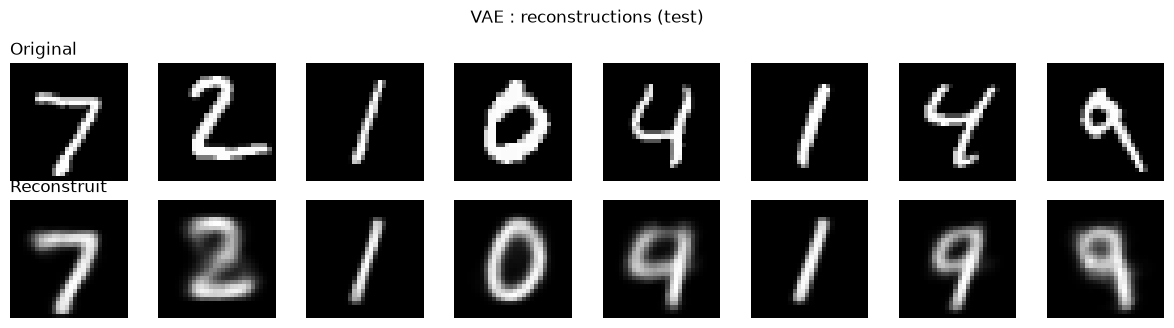

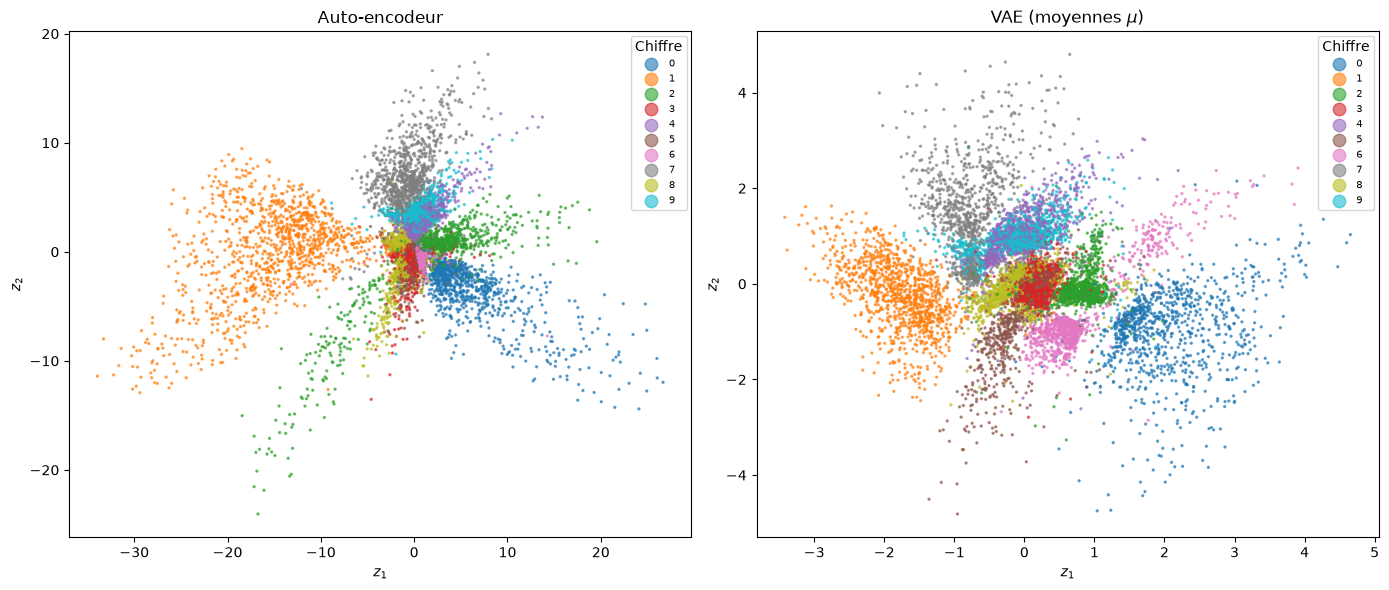

VAE - moyenne des codes : [0.07969226 0.0743316 ]  écart-type : [1.07394   1.0362793]


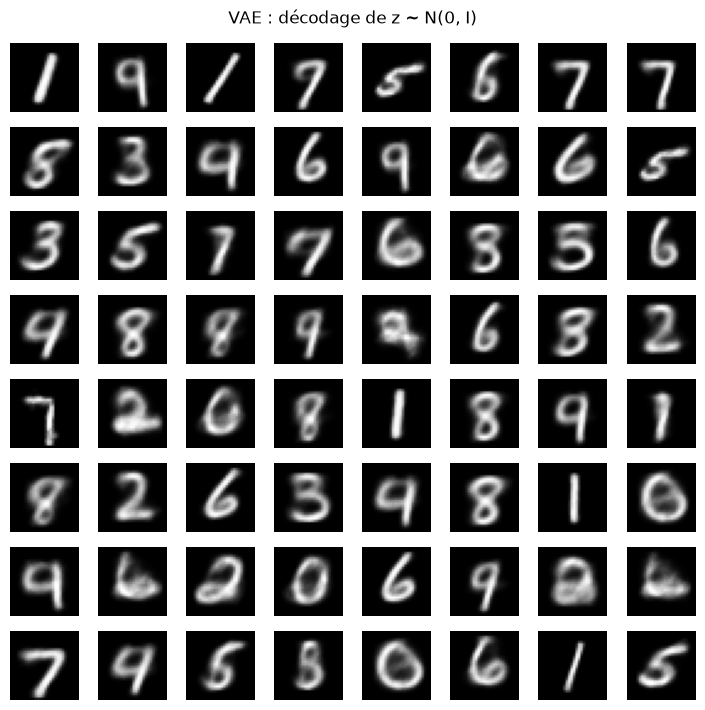

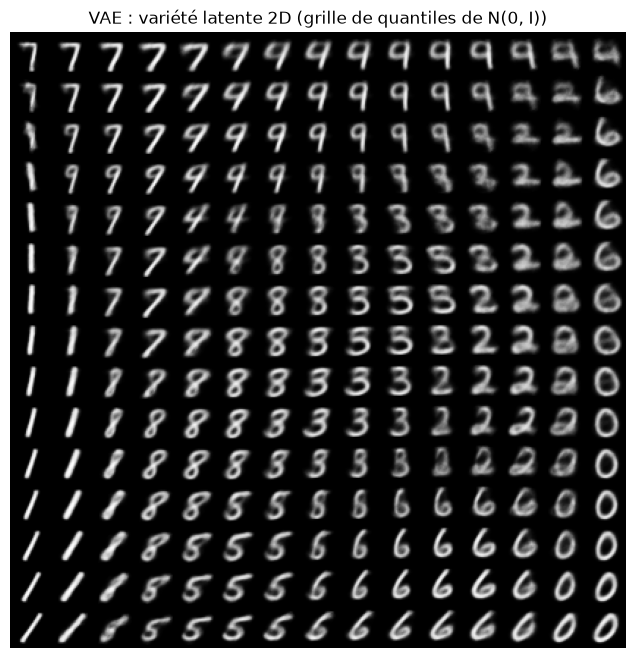

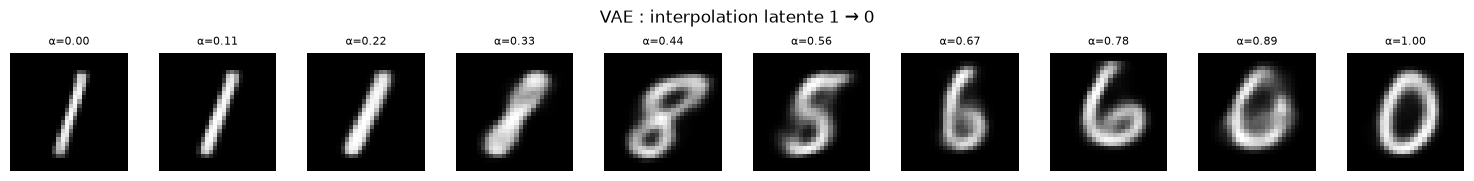

In [12]:
vae.eval()

# 1) Reconstructions (on utilise mu, sans bruit, pour reconstruire)
show_reconstructions(lambda x: vae.decoder(vae.encode(x)[0]), "VAE : reconstructions (test)")

# 2) Espace latent : AE vs VAE côte à côte
z_vae, y_vae = encode_dataset(lambda x: vae.encode(x)[0], test_loader)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_latent(z_ae, y_ae, "Auto-encodeur", axes[0])
plot_latent(z_vae, y_vae, "VAE (moyennes $\\mu$)", axes[1])
plt.tight_layout()
plt.show()
print("VAE - moyenne des codes :", z_vae.mean(dim=0).numpy(), " écart-type :", z_vae.std(dim=0).numpy())

# 3) Génération : z ~ N(0, I) -> décodeur. Comparaison directe avec l'AE.
with torch.no_grad():
    z_rand = torch.randn(64, LATENT_DIM, device=device)
    samples_vae = vae.decoder(z_rand).cpu()
show_grid(samples_vae, "VAE : décodage de z ~ N(0, I)", nrow=8)

# 4) Variété apprise : grille régulière en quantiles de N(0, 1)
n = 15
q = torch.linspace(0.05, 0.95, n)
grid = torch.distributions.Normal(0, 1).icdf(q)
zz = torch.stack(torch.meshgrid(grid, grid.flip(0), indexing="xy"), dim=-1).view(-1, 2)
with torch.no_grad():
    manifold = vae.decoder(zz.to(device)).cpu().view(n, n, 28, 28)
canvas = manifold.permute(0, 2, 1, 3).reshape(n * 28, n * 28)
plt.figure(figsize=(8, 8))
plt.imshow(canvas, cmap="gray")
plt.title("VAE : variété latente 2D (grille de quantiles de N(0, I))")
plt.axis("off")
plt.show()

# 5) Interpolation linéaire dans l'espace latent entre deux images de test
x_test, y_test = next(iter(test_loader))
i_a = (y_test == 1).nonzero()[0].item()
i_b = (y_test == 0).nonzero()[0].item()
with torch.no_grad():
    mu_a = vae.encode(x_test[i_a : i_a + 1].to(device))[0]
    mu_b = vae.encode(x_test[i_b : i_b + 1].to(device))[0]
    alphas = torch.linspace(0, 1, 10, device=device).view(-1, 1)
    interp = vae.decoder((1 - alphas) * mu_a + alphas * mu_b).cpu()
fig, axes = plt.subplots(1, 10, figsize=(15, 1.8))
for ax, img, a in zip(axes, interp, alphas.cpu()):
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(f"α={a.item():.2f}", fontsize=8)
    ax.axis("off")
plt.suptitle("VAE : interpolation latente 1 → 0")
plt.tight_layout()
plt.show()

**Observations.**

- **Espace latent** : grâce au terme KL, les codes sont centrés et d'écart-type ≈ 1 sur chaque axe (contre ≈ 6 et ≈ 4 pour l'AE). Les classes sont regroupées de manière compacte autour de l'origine, sans grands trous.
- **Génération** : en tirant $z \sim \mathcal{N}(0, I)$, on obtient cette fois **toutes les classes** (y compris les 1 et les 0, absents chez l'AE), car l'*a priori* correspond à la distribution des codes.
- **Variété latente** : la grille montre des transitions continues et douces entre chiffres (1 → 7 → 9, 3 → 5 → 6 → 0…) : tout point de l'espace latent se décode en une image plausible.
- **Interpolation** : passer linéairement d'un code à un autre produit une transformation progressive cohérente.
- **Compromis** : les images restent floues — le KL régularise au prix d'une reconstruction un peu moins fidèle, et $d = 2$ limite fortement la capacité. Une dimension latente plus grande (ex. 16–32) améliorerait la netteté.

## Conclusion

| Modèle | Apprend | Supervisé | Peut générer |
|---|---|---|---|
| Classifieur (CNN) | $p(y \mid x)$ | oui | non |
| Auto-encodeur | compression $x \to z \to \hat{x}$ | non | mal (latent sans structure connue) |
| VAE | $p_\theta(x) = \int p_\theta(x \mid z)\,p(z)\,dz$ (via l'ELBO) | non | oui, $z \sim \mathcal{N}(0, I)$ |